# Example 4: I have the raw traces and their processed quantities on disk, side by side

*An example for the `goldpan` / `goldsluice` note. Draft prepared with Claude Code for A. Villano, 2026-10-29.*

**The goal.** The same picture as Example 3, a trace next to its RQs with the RQs marked on it, but now the quantities already exist: `goldsluice` processed the pulses earlier and wrote the quantities to disk. Nothing is computed here. `ds.read()` reads the traces and the processed quantities of the same events together, as one `Events`.

**The data here are made up.** The pair is `synthetic-goldpan/` (the traces) and `synthetic-quantities/out/` (the quantities `goldsluice` made from them); the definition file `synthetic-quantities/synthetic.dataset.toml` names both. For your own data, point `DEFINITION` at your definition file: the one that `goldsluice run` used.

Needs `goldpan` (installed by `requirements.txt`). Run with the `darkmatter_cli_env` kernel.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from goldpan.dataset import Dataset

In [2]:
DEFINITION = Path("synthetic-quantities") / "synthetic.dataset.toml"

ds = Dataset.open(DEFINITION)
events = ds.read()                         # the pulses, with the processed quantities attached: one Events
config = events.detector.readout.segments[0].config

print(events)
print("channels:  ", list(events.detector.channel_names()))

Events(detector='NSDF', n_events=14, traces=[('Side2pA', 'main'), ('Side2pB', 'main'), ('Side2pC', 'main'), ('Side2pD', 'main'), ('Side2pE', 'main'), ('Side2pF', 'main')], quantities=['series', 'dump', 'event', 'trigger_type', 't_trigger', 'Side2pC', 'Side2pF', 'Side2pE', 'Side2pB', 'Side2pA', 'Side2pD'])
channels:   ['Side2pC', 'Side2pF', 'Side2pE', 'Side2pB', 'Side2pA', 'Side2pD']


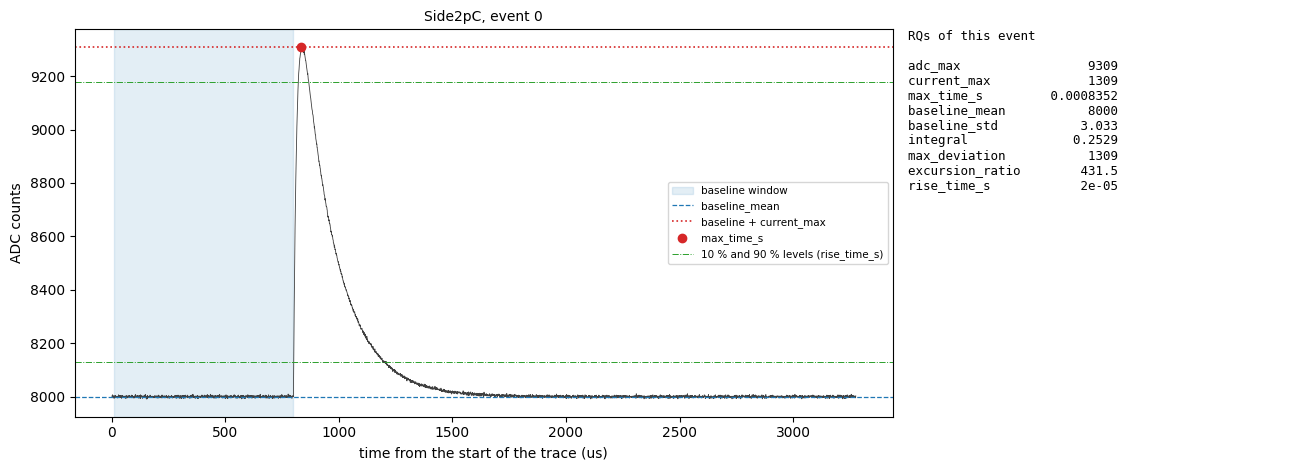

In [3]:
# One event, its trace on the left and its RQs on the right, each RQ marked on the trace. The RQs are read, not computed.
channel = "Side2pC"
rq = {name: np.asarray(events.quantities[channel][name], dtype=float) for name in events.quantities[channel].fields}
traces = events.trace(channel).astype(float)

i = int(np.argmax(rq["current_max"]))                              # the event with the largest pulse in this channel
trace = traces[i]
t_us = np.arange(len(trace)) * config.sample_period_s * 1e6
lo_s, hi_s = config.glitch_samples, config.pretrigger_samples      # the baseline window, in samples
base, peak = rq["baseline_mean"][i], rq["current_max"][i]

fig, (ax, axt) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw=dict(width_ratios=[2.2, 1]))
ax.plot(t_us, trace, lw=0.6, color="0.25")
ax.axvspan(t_us[lo_s], t_us[hi_s], color="C0", alpha=0.12, label="baseline window")
ax.axhline(base, color="C0", ls="--", lw=0.9, label="baseline_mean")
ax.axhline(base + peak, color="C3", ls=":", lw=1.2, label="baseline + current_max")
ax.plot(rq["max_time_s"][i] * 1e6, trace.max(), "o", color="C3", ms=6, label="max_time_s")
for frac in (0.1, 0.9):
    ax.axhline(base + frac * peak, color="C2", ls="-.", lw=0.7)
ax.plot([], [], color="C2", ls="-.", lw=0.7, label="10 % and 90 % levels (rise_time_s)")
ax.set_xlabel("time from the start of the trace (us)")
ax.set_ylabel("ADC counts")
ax.set_title(f"{channel}, event {i}", fontsize=10)
ax.legend(fontsize=7.5, loc="center right")

axt.axis("off")
rows = [f"{name:<16}{rq[name][i]:>12.4g}" for name in rq]
axt.text(0, 1, "RQs of this event" + chr(10) * 2 + chr(10).join(rows), va="top", family="monospace", fontsize=9)
fig.tight_layout()
plt.show()

**What this shows.** The figure is the one of Example 3, and the numbers in the table are the same, but here they come from the files `goldsluice` wrote and not from a computation in the notebook. That is the usual situation once a series has been processed: the quantities are on disk, the traces are on disk, and `ds.read()` joins them event by event. To pick events by their quantities (a cut) and look at their traces, take `events.select(mask)` with a mask built from `events.quantities`.